# CTU-13 Botnet Detection – Modelling (Scenario 1)

This notebook is dedicated to modelling for my second capstone idea, botnet detection. I will be using my cleaned dataset to answer the question: **Can machine learning help us identify malicious botnet traffic?**

The dataset contains 71,219 labelled network flows from CTU-13 Scenario 1 (Neris). The target is binary: `0` for Normal and `1` for Botnet. Background traffic is not included in this experiment.

To run the notebook in Google Colab, upload the cleaned `ml_dataset.csv` file to `/content/` first.

## 1. Dataset inspection

### 1.1 Loading the cleaned dataset

In [ ]:
import pandas as pd

In [ ]:
# Reading the data
df = pd.read_csv('/content/ml_dataset.csv')

In [ ]:
#
df.head()

,StartTime,Dur,Proto,SrcAddr,Sport,Dir,DstAddr,Dport,State,sTos,dTos,TotPkts,TotBytes,SrcBytes,Label,traffic_type,target
0,2011/08/10 09:46:53.160043,0.000000,udp,147.32.80.9,53,->,147.32.86.111,54230,INT,0.0,NaN,1,141,141,flow=From-Normal-V42-UDP-CVUT-DNS-Server,From-Normal,0
1,2011/08/10 09:46:54.045343,0.000000,udp,147.32.80.9,53,->,147.32.86.111,58314,INT,0.0,NaN,1,247,247,flow=From-Normal-V42-UDP-CVUT-DNS-Server,From-Normal,0
2,2011/08/10 09:46:54.460552,0.000000,udp,147.32.80.9,53,->,147.32.86.111,54823,INT,0.0,NaN,1,173,173,flow=From-Normal-V42-UDP-CVUT-DNS-Server,From-Normal,0
3,2011/08/10 09:46:54.779125,0.000291,udp,147.32.84.134,40693,<->,147.32.80.9,53,CON,0.0,0.0,2,207,72,flow=From-Normal-V42-Jist,From-Normal,0
4,2011/08/10 09:46:54.779641,0.000321,udp,147.32.84.134,47415,<->,147.32.80.9,53,CON,0.0,0.0,2,247,72,flow=From-Normal-V42-Jist,From-Normal,0


In [ ]:
# Looking at the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71219 entries, 0 to 71218
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   StartTime     71219 non-null  object 
 1   Dur           71219 non-null  float64
 2   Proto         71219 non-null  object 
 3   SrcAddr       71219 non-null  object 
 4   Sport         71206 non-null  object 
 5   Dir           71219 non-null  object 
 6   DstAddr       71219 non-null  object 
 7   Dport         71206 non-null  object 
 8   State         71219 non-null  object 
 9   sTos          71206 non-null  float64
 10  dTos          58211 non-null  float64
 11  TotPkts       71219 non-null  int64  
 12  TotBytes      71219 non-null  int64  
 13  SrcBytes      71219 non-null  int64  
 14  Label         71219 non-null  object 
 15  traffic_type  71219 non-null  object 
 16  target        71219 non-null  int64  
dtypes: float64(3), int64(4), object(10)
memory usage: 9.2+ MB


### 1.2 Port analysis

<Axes: ylabel='Sport,Dport'>

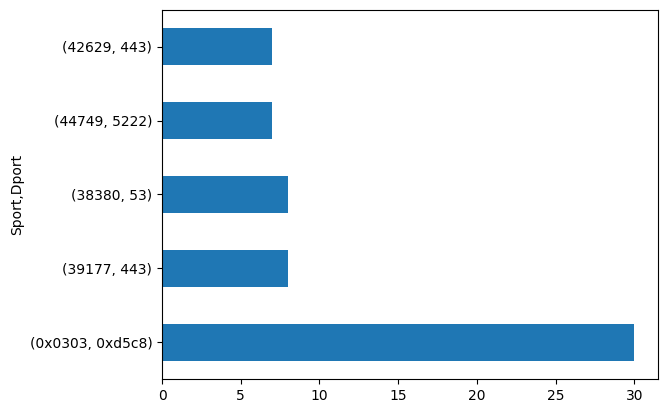

In [ ]:
# I see that there are some ports that are inaproprietly written
df[df['traffic_type']=='From-Normal'][['Sport','Dport']].value_counts().sort_values(ascending=False).head(5).plot(kind='barh')

<Axes: ylabel='Sport,Dport'>

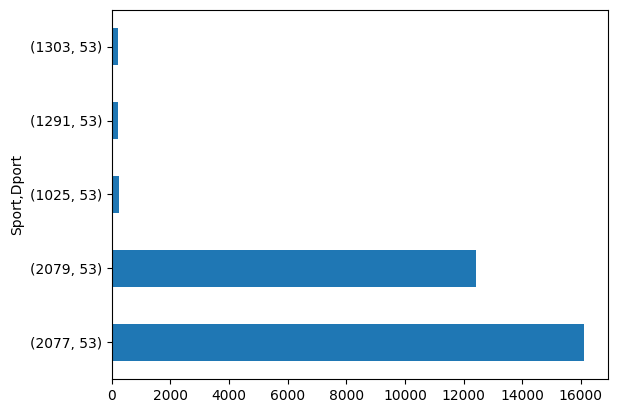

In [ ]:
# From this table I see that botnet traffic communication usually comes from unstandardized ports
df[df['traffic_type']=='From-Botnet'][['Sport','Dport']].value_counts().sort_values(ascending=False).head(5).plot(kind='barh')

This is an important finding, in my opinion. Most botnet flows in this scenario come from source ports 2077 and 2079 and communicate with destination port 53. This is a big clue, but these ports alone do not prove that the traffic is malicious.

Some port values are also written in hexadecimal. For now, I will remove `Sport` and `Dport` to avoid relying on port patterns that may be specific to this scenario.

## 2. Data splitting and feature selection

### 2.1 Traffic distribution over time

In [ ]:
df['StartTime'] = pd.to_datetime(df['StartTime'])

In [ ]:
print(df['StartTime'].min())
print(df['StartTime'].max())

2011-08-10 09:46:53.160043
2011-08-10 15:54:07.198435


In [ ]:
df['StartTime'].dt.floor('h')

,StartTime
0,2011-08-10 09:00:00
1,2011-08-10 09:00:00
2,2011-08-10 09:00:00
3,2011-08-10 09:00:00
4,2011-08-10 09:00:00
...,...
71214,2011-08-10 15:00:00
71215,2011-08-10 15:00:00
71216,2011-08-10 15:00:00
71217,2011-08-10 15:00:00


In [ ]:
hourly_traffic = pd.crosstab(
    df['StartTime'].dt.floor('h'),
    df['traffic_type']
)

display(hourly_traffic)

traffic_type,From-Botnet,From-Normal
StartTime,,
2011-08-10 09:00:00,0,1696
2011-08-10 10:00:00,0,3346
2011-08-10 11:00:00,2825,3868
2011-08-10 12:00:00,5165,6974
2011-08-10 13:00:00,20995,6424
2011-08-10 14:00:00,2526,4141
2011-08-10 15:00:00,9450,3809


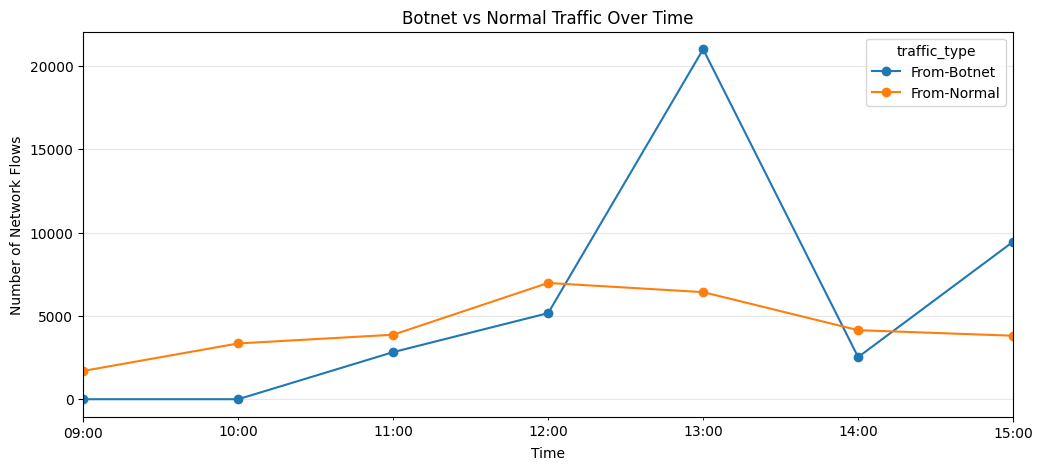

In [ ]:
# There is not a certain trend that we can observe,
# I see that botnet traffic begins at 1000 and spikes at 1300, lowers at 1400
# but reappears eventually
import matplotlib.pyplot as plt

hourly_traffic.plot(
    kind='line',
    figsize=(12, 5),
    marker='o'
)

plt.title('Botnet vs Normal Traffic Over Time')
plt.xlabel('Time')
plt.ylabel('Number of Network Flows')
plt.grid(alpha=0.3)
plt.show()

Based on this graph, I will split the data in the following order:

- Training: before 14:00 (51,293 flows)
- Validation: 14:00 to before 15:00 (6,667 flows)
- Test: from 15:00 onwards (13,259 flows)

The hourly table shows that the first botnet flows appear in the 11:00 hour, with a peak at 13:00. A chronological split allows me to train on earlier traffic and evaluate on later traffic. All three sets contain both classes.

### 2.2 Feature selection and target

For modelling I intend to use all columns with the exception of the following:

- **StartTime** – useful for splitting the data, but excluded as a direct predictor.
- **SrcAddr** and **DstAddr** – there is one infected host in this scenario, so the model could learn its IP address instead of traffic behaviour.
- **Sport** and **Dport** – excluded for the reasons discussed above.
- **traffic_type**, **Label** and **target** – excluded from X because they contain or define the answer we want the model to predict.

The `target` column will be used as y. This leaves nine input features.

In [ ]:
train_df = df[
    df['StartTime'] < '2011-08-10 14:00:00'
].copy()

val_df = df[
    (df['StartTime'] >= '2011-08-10 14:00:00') &
    (df['StartTime'] < '2011-08-10 15:00:00')
].copy()

test_df = df[
    df['StartTime'] >= '2011-08-10 15:00:00'
].copy()

In [ ]:
train_df['target'].value_counts()

,count
target,
1,28985
0,22308


In [ ]:
val_df['target'].value_counts()

,count
target,
0,4141
1,2526


In [ ]:
test_df['target'].value_counts()

,count
target,
1,9450
0,3809


In [ ]:
drop_cols = ['StartTime', 'SrcAddr', 'DstAddr', 'Sport', 'Dport', 'Label', 'traffic_type', 'target']

X_train = train_df.drop(columns=drop_cols)
y_train = train_df['target']

X_val = val_df.drop(columns=drop_cols)
y_val = val_df['target']

X_test = test_df.drop(columns=drop_cols)
y_test = test_df['target']

In [ ]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(51293, 9)
(6667, 9)
(13259, 9)


## 3. Data preprocessing

### 3.1 Data types and missing values

In [ ]:
X_train.dtypes

,0
Dur,float64
Proto,object
Dir,object
State,object
sTos,float64
dTos,float64
TotPkts,int64
TotBytes,int64
SrcBytes,int64


In [ ]:
numeric_cols = ['Dur', 'sTos', 'dTos', 'TotPkts', 'TotBytes', 'SrcBytes']
categorical_cols = ['Proto', 'Dir', 'State']

In [ ]:
X_train.isna().sum()

,0
Dur,0
Proto,0
Dir,0
State,0
sTos,10
dTos,8336
TotPkts,0
TotBytes,0
SrcBytes,0


In [ ]:
X_val.isna().sum()

,0
Dur,0
Proto,0
Dir,0
State,0
sTos,2
dTos,2256
TotPkts,0
TotBytes,0
SrcBytes,0


In [ ]:
X_test.isna().sum()

,0
Dur,0
Proto,0
Dir,0
State,0
sTos,1
dTos,2416
TotPkts,0
TotBytes,0
SrcBytes,0


### 3.2 Preprocessing pipelines

The numeric pipeline fills missing values using the training median, adds missing-value indicators and scales the features. The categorical pipeline uses the most frequent value for missing data and one-hot encoding. Both are fitted as part of the model pipeline using the training set.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [ ]:
numeric_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median',add_indicator=True)),
        ('scaler', StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, numeric_cols),
        ('cat', categorical_pipeline, categorical_cols)
    ]
)

In [ ]:
print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Dur', 'sTos', 'dTos', 'TotPkts', 'TotBytes',
                                  'SrcBytes']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Proto', 'Dir', 'State'])])


## 4. Model training and validation

### 4.1 Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [ ]:
lr_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Dur', 'sTos', 'dTos',
                                                   'TotPkts', 'TotBytes',
                                                   'SrcBytes']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Proto', 'Dir', 'State'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [ ]:
y_pred_lr = lr_pipeline.predict(X_val)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score
)

print(f'Accuracy: {accuracy_score(y_val, y_pred_lr)}')
print(f'Precision: {precision_score(y_val, y_pred_lr)}')
print(f'Recall Score: {recall_score(y_val, y_pred_lr)}')

Accuracy: 0.5611219439028049
Precision: 0.4613601236476043
Recall Score: 0.9453681710213777


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    y_pred_lr,
    target_names=['Normal', 'Botnet'],
    digits=4
))

              precision    recall  f1-score   support

      Normal     0.9074    0.3267    0.4805      4141
      Botnet     0.4614    0.9454    0.6201      2526

    accuracy                         0.5611      6667
   macro avg     0.6844    0.6361    0.5503      6667
weighted avg     0.7384    0.5611    0.5334      6667



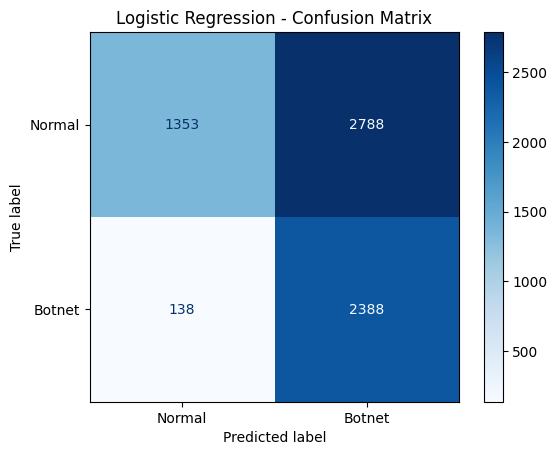

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_lr,
    display_labels=['Normal', 'Botnet'],
    cmap='Blues',
    values_format='d'
)

plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [ ]:
print("Train Accuracy:",
      lr_pipeline.score(X_train, y_train))

print("Validation Accuracy:",
      lr_pipeline.score(X_val, y_val))

Train Accuracy: 0.6806386836410426
Validation Accuracy: 0.5611219439028049


### 4.2 Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('classifier', DecisionTreeClassifier(
            random_state=42,
        ))
    ]
)

In [ ]:
dt_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Dur', 'sTos', 'dTos',
                                                   'TotPkts', 'TotBytes',
                                                   'SrcBytes']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Proto', 'Dir', 'State'])])),
                ('classifier', DecisionTreeClassifier(random_state=42))])

In [ ]:
y_pred_dt = dt_pipeline.predict(X_val)

In [ ]:
print(classification_report(
    y_val,
    y_pred_dt,
    target_names=['Normal', 'Botnet'],
    digits=4
))

              precision    recall  f1-score   support

      Normal     0.9917    0.9254    0.9574      4141
      Botnet     0.8898    0.9873    0.9360      2526

    accuracy                         0.9489      6667
   macro avg     0.9407    0.9564    0.9467      6667
weighted avg     0.9531    0.9489    0.9493      6667



              precision    recall  f1-score   support

      Normal       0.99      0.93      0.96      4141
      Botnet       0.89      0.99      0.94      2526

    accuracy                           0.95      6667
   macro avg       0.94      0.96      0.95      6667
weighted avg       0.95      0.95      0.95      6667



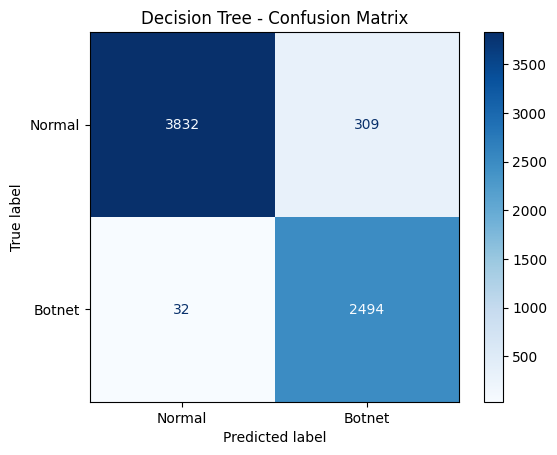

In [ ]:
print(classification_report(
    y_val,
    y_pred_dt,
    target_names=['Normal', 'Botnet']
))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_dt,
    display_labels=['Normal','Botnet'],
    cmap='Blues'
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()

I am very pleased with the results compared to Logistic Regression. Before moving on to Random Forest, I want to check the complexity of this tree.

In [ ]:
print("Train Accuracy:",
      dt_pipeline.score(X_train, y_train))

print("Validation Accuracy:",
      dt_pipeline.score(X_val, y_val))

tree = dt_pipeline.named_steps['classifier']

print("Tree Depth:", tree.get_depth())
print("Number of Leaves:", tree.get_n_leaves())

Train Accuracy: 0.9992981498450081
Validation Accuracy: 0.9488525573721314
Tree Depth: 30
Number of Leaves: 2545


### 4.3 Decision Tree (max_depth=5)

Before Random Forest, I want to try to make a simpler tree with better or similar results. I will specify the maximum depth to be 5 and see what happens.

In [ ]:
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier

dt5_pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('classifier', DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        ))
    ]
)

dt5_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Dur', 'sTos', 'dTos',
                                                   'TotPkts', 'TotBytes',
                                                   'SrcBytes']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Proto', 'Dir', 'State'])])),
                ('classifier',
                 DecisionTreeClassifier(max_depth=5, random_state=42))])

In [ ]:
print("Train Accuracy:",
      dt5_pipeline.score(X_train, y_train))

print("Validation Accuracy:",
      dt5_pipeline.score(X_val, y_val))

tree5 = dt5_pipeline.named_steps['classifier']

print("Tree Depth:", tree5.get_depth())
print("Number of Leaves:", tree5.get_n_leaves())

Train Accuracy: 0.9086620006628585
Validation Accuracy: 0.9109044547772611
Tree Depth: 5
Number of Leaves: 29


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_dt5 = dt5_pipeline.predict(X_val)

print(classification_report(y_val, y_pred_dt5))
print(confusion_matrix(y_val, y_pred_dt5))

              precision    recall  f1-score   support

           0       0.95      0.90      0.93      4141
           1       0.85      0.92      0.89      2526

    accuracy                           0.91      6667
   macro avg       0.90      0.91      0.91      6667
weighted avg       0.91      0.91      0.91      6667

[[3739  402]
 [ 192 2334]]


### 4.4 Random Forest

The smaller tree has only 29 leaves instead of 2,545. Its validation accuracy is still good (91.09%), but it misses more botnet flows (192 instead of 32). I will now try Random Forest without changing the input features or the data split.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Dur', 'sTos', 'dTos',
                                                   'TotPkts', 'TotBytes',
                                                   'SrcBytes']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Proto', 'Dir', 'State'])])),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=42))])

In [ ]:
print("Train Accuracy:",
      rf_pipeline.score(X_train, y_train))

print("Validation Accuracy:",
      rf_pipeline.score(X_val, y_val))

Train Accuracy: 0.9992786540073694
Validation Accuracy: 0.9596520173991301


              precision    recall  f1-score   support

      Normal       0.99      0.94      0.97      4141
      Attack       0.91      0.99      0.95      2526

    accuracy                           0.96      6667
   macro avg       0.95      0.97      0.96      6667
weighted avg       0.96      0.96      0.96      6667



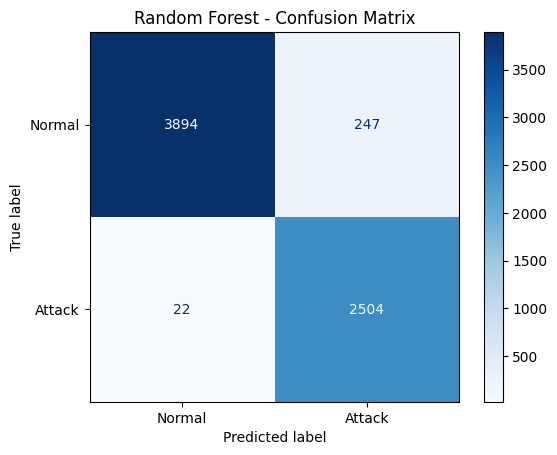

In [ ]:
y_pred_rf = rf_pipeline.predict(X_val)

print(classification_report(
    y_val,
    y_pred_rf,
    target_names=['Normal', 'Attack']
))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_rf,
    display_labels=['Normal', 'Attack'],
    cmap='Blues',
    values_format='d'
)

plt.title('Random Forest - Confusion Matrix')
plt.show()

## 5. Model selection and feature importance

| Model | Train accuracy | Validation accuracy |
| --- | ---: | ---: |
| Logistic Regression | 68.06% | 56.11% |
| Decision Tree | 99.93% | 94.89% |
| Decision Tree (max_depth=5) | 90.87% | 91.09% |
| Random Forest | 99.93% | 95.97% |

Random Forest performed best on the validation set. I will use it as my final model and look at which features it relies on the most.

In [ ]:
feature_names = rf_pipeline.named_steps[
    'preprocessing'
].get_feature_names_out()

importances = rf_pipeline.named_steps[
    'classifier'
].feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
0,num__Dur,0.429844
4,num__TotBytes,0.243596
5,num__SrcBytes,0.133235
3,num__TotPkts,0.048246
7,num__missingindicator_dTos,0.029135
63,cat__State_S_,0.019974
28,cat__State_FSPA_FSPA,0.014127
17,cat__State_CON,0.013050
12,cat__Dir_ ->,0.010855
40,cat__State_INT,0.010485


Duration, total bytes and source bytes together account for about 81% of the reported feature importance. This is consistent with the idea that the model relies heavily on flow-level characteristics. Feature importance does not establish causation.

## 6. Final test evaluation

Random Forest was selected using the validation results. I will now evaluate the trained model on the last time period without fitting it again.

              precision    recall  f1-score   support

      Normal       0.87      0.95      0.91      3809
      Attack       0.98      0.95      0.96      9450

    accuracy                           0.95     13259
   macro avg       0.93      0.95      0.94     13259
weighted avg       0.95      0.95      0.95     13259



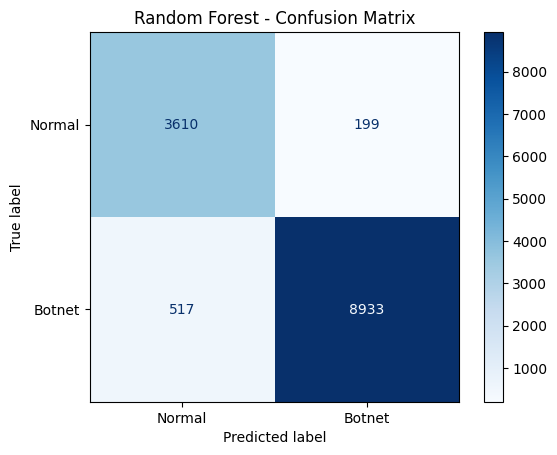

In [ ]:
y_pred_rf_test = rf_pipeline.predict(X_test)

print(classification_report(
    y_test,
    y_pred_rf_test,
    target_names=['Normal', 'Attack']
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf_test,
    display_labels=['Normal', 'Botnet'],
    cmap='Blues',
    values_format='d'
)

plt.title('Random Forest - Confusion Matrix')
plt.show()

In [ ]:
print("Train Accuracy:",
      rf_pipeline.score(X_train, y_train))

print("Test Accuracy:",
      rf_pipeline.score(X_test, y_test))

Train Accuracy: 0.9992786540073694
Test Accuracy: 0.9459989441134324


## 7. Error analysis

### 7.1 Identifying incorrect predictions

In [ ]:
test_results = test_df.copy()

test_results['prediction'] = rf_pipeline.predict(X_test)

false_negatives = test_results[
    (test_results['target'] == 1) &
    (test_results['prediction'] == 0)
]

false_positives = test_results[
    (test_results['target'] == 0) &
    (test_results['prediction'] == 1)
]

true_positives = test_results[
    (test_results['target'] == 1) &
    (test_results['prediction'] == 1)
]

true_negatives = test_results[
    (test_results['target'] == 0) &
    (test_results['prediction'] == 0)
]

print("False Negatives:", len(false_negatives))
print("False Positives:", len(false_positives))
print("True Positives:", len(true_positives))
print("True Negatives:", len(true_negatives))

False Negatives: 517
False Positives: 199
True Positives: 8933
True Negatives: 3610


### 7.2 False negatives by traffic label

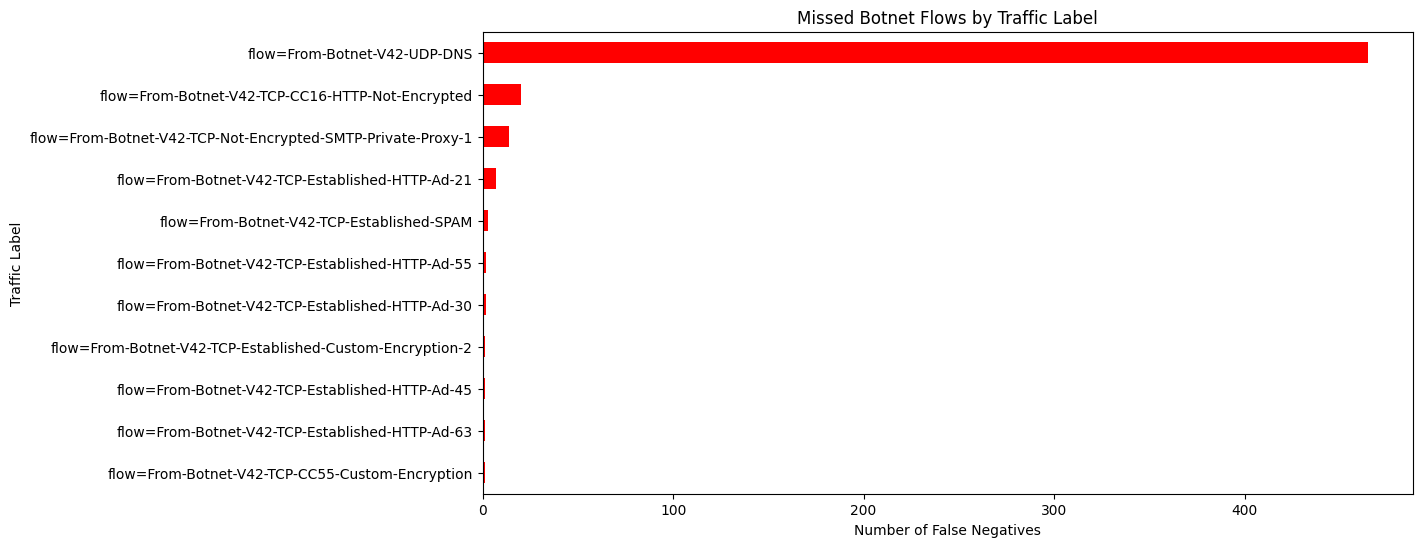

In [ ]:
false_negatives['Label'].value_counts().plot(
    kind='barh',
    figsize=(12, 6),
    color='red'
)

plt.title('Missed Botnet Flows by Traffic Label')
plt.xlabel('Number of False Negatives')
plt.ylabel('Traffic Label')
plt.gca().invert_yaxis()
plt.show()

In [ ]:
botnet_flows = test_results[
    test_results['target'] == 1
]

fn_by_label = pd.crosstab(
    botnet_flows['Label'],
    botnet_flows['prediction']
).reindex(columns=[0, 1], fill_value=0)

fn_by_label.columns = [
    'False Negatives',
    'True Positives'
]

fn_by_label['Total'] = (
    fn_by_label['False Negatives'] +
    fn_by_label['True Positives']
)

fn_by_label['Miss Rate (%)'] = (
    fn_by_label['False Negatives'] /
    fn_by_label['Total'] * 100
)

fn_by_label.sort_values(
    'Miss Rate (%)',
    ascending=False
).round(2)

,False Negatives,True Positives,Total,Miss Rate (%)
Label,,,,
flow=From-Botnet-V42-TCP-CC55-Custom-Encryption,1,0,1,100.00
flow=From-Botnet-V42-TCP-Established-Custom-Encryption-2,1,0,1,100.00
flow=From-Botnet-V42-TCP-Established-HTTP-Ad-21,7,5,12,58.33
flow=From-Botnet-V42-TCP-CC16-HTTP-Not-Encrypted,20,43,63,31.75
flow=From-Botnet-V42-TCP-Established-HTTP-Ad-30,2,6,8,25.00
flow=From-Botnet-V42-TCP-Established-HTTP-Ad-45,1,4,5,20.00
flow=From-Botnet-V42-TCP-Established-HTTP-Ad-55,2,9,11,18.18
flow=From-Botnet-V42-TCP-Not-Encrypted-SMTP-Private-Proxy-1,14,69,83,16.87
flow=From-Botnet-V42-TCP-Established-SPAM,3,25,28,10.71


### 7.3 Missed vs detected botnet flows

In [ ]:
features = [
    'Dur',
    'TotBytes',
    'SrcBytes',
    'TotPkts'
]

fn_comparison = pd.DataFrame({
    'False Negatives Mean':
        false_negatives[features].mean(),

    'True Positives Mean':
        true_positives[features].mean(),

    'False Negatives Median':
        false_negatives[features].median(),

    'True Positives Median':
        true_positives[features].median()
})

fn_comparison.round(4)

,False Negatives Mean,True Positives Mean,False Negatives Median,True Positives Median
Dur,15.1048,9.8941,0.0005,0.067
TotBytes,2270.7505,881.2327,223.0000,203.000
SrcBytes,704.2689,358.6552,74.0000,74.000
TotPkts,13.0774,3.4073,2.0000,2.000


### 7.4 Destination ports of missed botnet flows

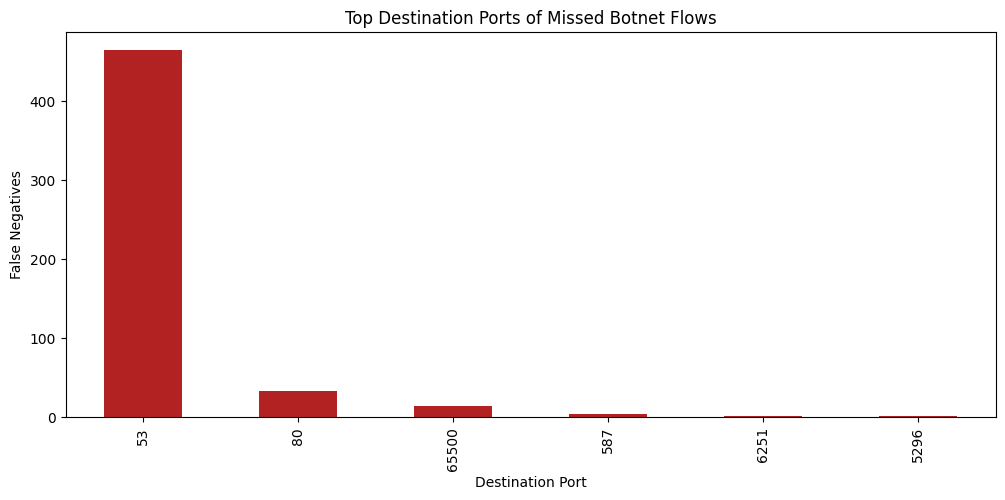

In [ ]:
false_negatives['Dport'].value_counts().head(15).plot(
    kind='bar',
    figsize=(12, 5),
    color='firebrick'
)

plt.title('Top Destination Ports of Missed Botnet Flows')
plt.xlabel('Destination Port')
plt.ylabel('False Negatives')
plt.show()

### 7.5 False positives and normal traffic

In [ ]:
false_positives['Label'].value_counts()

,count
Label,
flow=From-Normal-V42-Stribrek,114
flow=From-Normal-V42-Grill,82
flow=From-Normal-V42-Jist,1
flow=From-Normal-V42-UDP-CVUT-DNS-Server,1
flow=From-Normal-V42-CVUT-WebServer,1


In [ ]:
false_positives['Proto'].value_counts()

,count
Proto,
udp,193
tcp,6


In [ ]:
false_positives['Dport'].value_counts().head()

,count
Dport,
53,192
80,4
1863,1
443,1
38302,1


In [ ]:
normal_flows = test_results[
    test_results['target'] == 0
]

fp_by_label = pd.crosstab(
    normal_flows['Label'],
    normal_flows['prediction']
).reindex(columns=[0, 1], fill_value=0)

fp_by_label.columns = [
    'True Negatives',
    'False Positives'
]

fp_by_label['Total'] = (
    fp_by_label['True Negatives'] +
    fp_by_label['False Positives']
)

fp_by_label['False Positive Rate (%)'] = (
    fp_by_label['False Positives'] /
    fp_by_label['Total'] * 100
)

fp_by_label.sort_values(
    'False Positive Rate (%)',
    ascending=False
).round(2)

,True Negatives,False Positives,Total,False Positive Rate (%)
Label,,,,
flow=From-Normal-V42-Grill,815,82,897,9.14
flow=From-Normal-V42-Jist,16,1,17,5.88
flow=From-Normal-V42-CVUT-WebServer,21,1,22,4.55
flow=From-Normal-V42-Stribrek,2691,114,2805,4.06
flow=From-Normal-V42-UDP-CVUT-DNS-Server,67,1,68,1.47


In [ ]:
fp_comparison = pd.DataFrame({
    'False Positives Mean':
        false_positives[features].mean(),

    'True Negatives Mean':
        true_negatives[features].mean(),

    'False Positives Median':
        false_positives[features].median(),

    'True Negatives Median':
        true_negatives[features].median()
})

fp_comparison.round(4)

,False Positives Mean,True Negatives Mean,False Positives Median,True Negatives Median
Dur,0.8321,30.5367,0.0348,0.0005
TotBytes,1286.2412,32364.5269,234.0000,400.0000
SrcBytes,145.6382,1436.5623,76.0000,81.0000
TotPkts,3.4070,35.5183,2.0000,2.0000


### 7.6 Errors over time

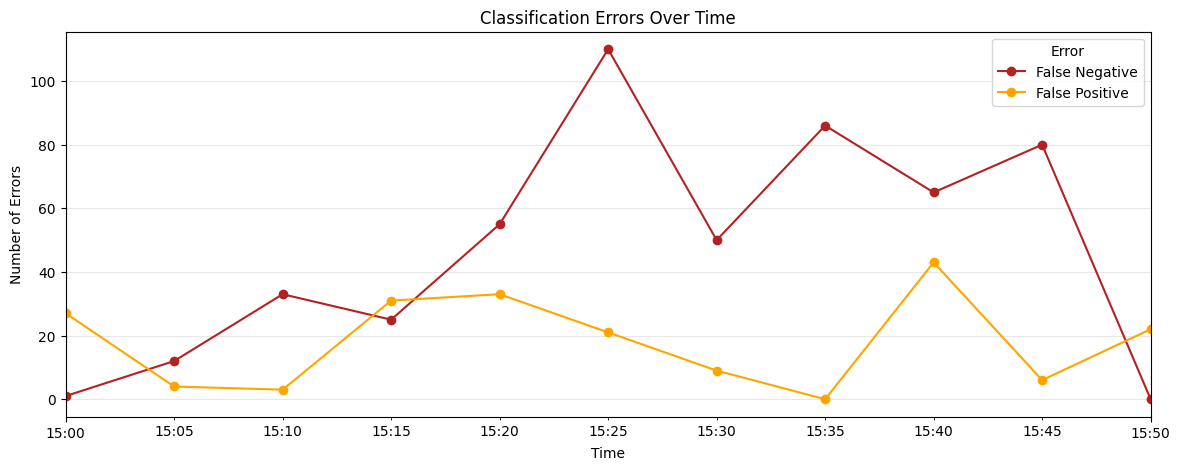

In [ ]:
errors = pd.concat([
    false_negatives.assign(Error='False Negative'),
    false_positives.assign(Error='False Positive')
])

errors_over_time = pd.crosstab(
    errors['StartTime'].dt.floor('5min'),
    errors['Error']
)

errors_over_time.plot(
    kind='line',
    figsize=(14, 5),
    marker='o',
    color=['firebrick', 'orange']
)

plt.title('Classification Errors Over Time')
plt.xlabel('Time')
plt.ylabel('Number of Errors')
plt.grid(alpha=0.3)
plt.show()

### 7.7 Main findings

- 465 of the 517 false negatives belong to the UDP-DNS label (about 90% of missed botnet flows). The miss rate for this label is 6.99%. Some smaller HTTP and SMTP categories have higher miss rates.
- The median duration of missed botnet flows is 0.0005 seconds, compared to 0.067 seconds for detected botnet flows.
- 192 of the 199 false positives use destination port 53. This suggests that distinguishing normal and botnet DNS-related traffic is a major challenge.
- Errors are not evenly distributed over time. The plot shows error counts, not error rates, so increased traffic volume could also explain the peaks.

These findings are useful for understanding where the model struggles, but I will not use the test results to tune the current model.

## 8. Final conclusion

The main objective of this project was to investigate whether machine learning could effectively distinguish botnet traffic from legitimate network traffic using network flow characteristics.

The CTU-13 dataset (Scenario 1 – Neris botnet) was used to develop and evaluate three machine learning algorithms: Logistic Regression, Decision Tree, and Random Forest.

Random Forest demonstrated the best validation performance and was selected as the final model, achieving the following results on previously unseen test data from the same scenario:

- **Accuracy:** 94.60%
- **Botnet Precision:** 97.82%
- **Botnet Recall:** 94.53%
- **True Positives:** 8,933
- **False Positives:** 199
- **False Negatives:** 517
- **False Positive Rate:** 5.22%

Feature importance analysis identified flow duration, total bytes, and source bytes as the most influential characteristics according to the model's impurity-based feature importance. Error analysis revealed that DNS-related traffic, particularly short UDP flows, represents a significant challenge. Similarities in flow characteristics may help explain these errors.

However, the model was trained and evaluated using a single botnet scenario, excluding background traffic. Its ability to generalize across different networks, botnet families, and real-world traffic distributions remains unverified. Therefore, the model should be considered a proof of concept only.

Future work could include cross-scenario evaluation, additional botnet families, more recent datasets, temporal traffic aggregation, and host-level behavioral analysis.

Overall, this project demonstrates that machine learning represents a promising complementary approach to traditional network intrusion detection.